# $\zeta(2)-\gamma^2$: Rivoal simultaneous recovery

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.meijer_g import MeijerG
from cmfs import second_compound

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
a0, a1, a2, b0, b1, b2, b3 = sp.symbols('a0:3 b0:4')
target = lambda: arb(2).zeta()-arb.const_euler()**2


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Rivoal (2009), simultaneous construction

[Rivoal (2009), Theorem 2, Proposition 21, and Section 9.1](https://rivoal.perso.math.cnrs.fr/articles/eulerconstant.pdf).

**CMF:** $G^{4,3}_{3,4}(-1)$, dual, rank 4. **Start:** $(0,0,0;0,0,0,0)$. **Direction:** $(0,0,0;1,1,1,1)$.
N is the source index.
**Readout:** $(P\,\wedge^2W\,w)/(Q\,\wedge^2W\,w)$ on the $2\times2$ minors of $W$, with $w=(0,0,0,1,-3,3)$;
this is the source's determinant ratio for $\zeta(2)-\gamma^2$.

In [2]:
cmf = MeijerG(4, 3, 3, 4, -1).dual()
start = {a0: 0, a1: 0, a2: 0, b0: 0, b1: 0, b2: 0, b3: 0}
trajectory = {a0: 0, a1: 0, a2: 0, b0: 1, b1: 1, b2: 1, b3: 1}
P, Q = Matrix([[0, -2, 0, -2, 0, 0]]), Matrix([[1, 0, 1, -1, 1, 1]])
w = Matrix([0, 0, 0, 1, -3, 3])
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * C * w)[0] / (Q * C * w)[0] for C in map(second_compound, walks)]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rivoal (2009), simultaneous'] = (DEPTHS, deltas)
accuracy['Rivoal (2009), simultaneous'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.913256679242


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

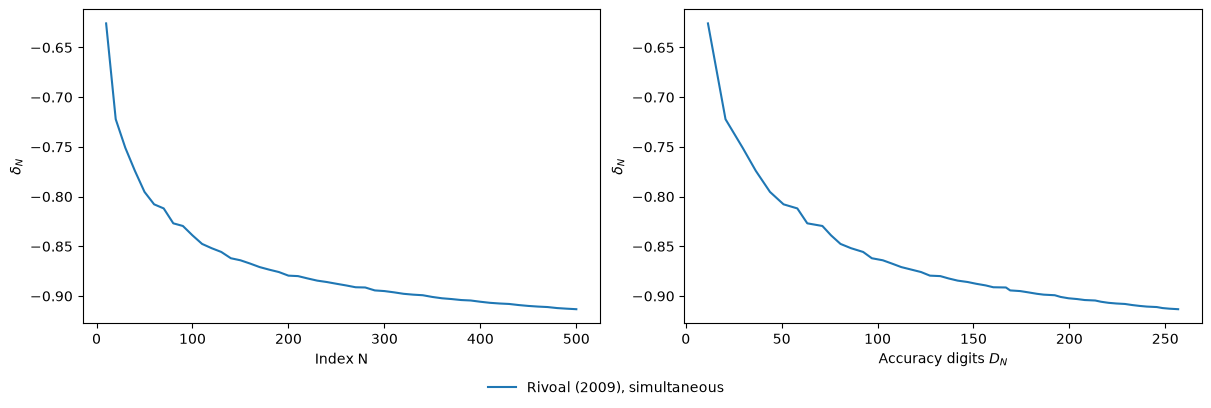

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [4]:
bounds = {
    'Rivoal (2009), simultaneous': 'Subexponential error bound; no irrationality-measure bound',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Rivoal (2009), simultaneous | Subexponential error bound; no irrationality-measure bound | -0.913256679242 (N = 500) |